## Adaline


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("iris_data.csv", index_col=0)
data = data[data['class'] != 'Iris-virginica']
X = data[['sepal length', 'petal length']].to_numpy()
y = np.where(data['class'] == 'Iris-setosa', 1, 0)
print(X.shape, y.shape)

(100, 2) (100,)


In [3]:
class Adaline:

    def __init__(self, eta=0.01, n_iter=50, random_state=1):
        self.eta = eta
        self.n_iter = n_iter
        self.random_state = random_state

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        self.w = rgen.normal(loc=0, scale=0.01, size=X.shape[1])
        self.b = 0.0
        self.losses_ = []

        for _ in range(self.n_iter):
            output = self.net_input(X)
            errors = y - output
            self.w = self.w + self.eta * 2 * X.T @ errors / X.shape[0]
            self.b = self.b + 2 * self.eta * errors.sum() / X.shape[0]
            self.losses_.append(((y - output) ** 2).sum() / X.shape[0])
        return self

    def net_input(self, X):
        return np.dot(X, self.w) + self.b


    def activation(self, z):
        return z

    def predict(self, X):
        return np.where(self.activation(self.net_input(X)) >= 0.5, 1, 0)


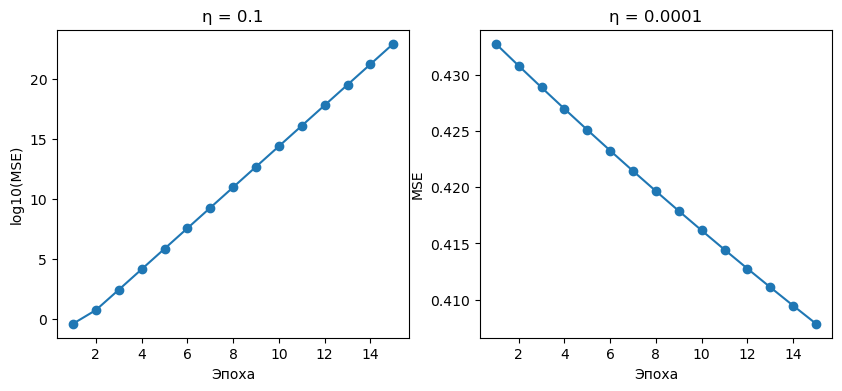

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ada1 = Adaline(eta=0.1, n_iter=15).fit(X, y)
ax[0].plot(range(1, len(ada1.losses_) + 1), np.log10(ada1.losses_), marker='o')
ax[0].set(xlabel='Эпоха', ylabel='log10(MSE)', title='η = 0.1')

ada2 = Adaline(eta=0.0001, n_iter=15).fit(X, y)
ax[1].plot(range(1, len(ada2.losses_) + 1), ada2.losses_, marker='o')
ax[1].set(xlabel='Эпоха', ylabel='MSE', title='η = 0.0001')
plt.show()

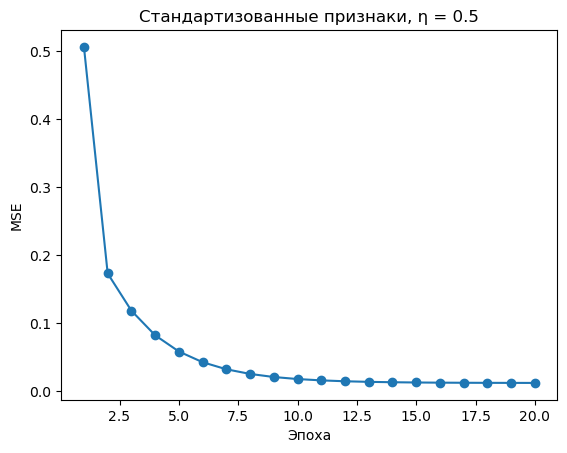

Accuracy: 100.00%


In [5]:
X_std = (X - X.mean(axis=0)) / X.std(axis=0)

ada = Adaline(eta=0.5, n_iter=20).fit(X_std, y)
plt.plot(range(1, len(ada.losses_) + 1), ada.losses_, marker='o')
plt.xlabel('Эпоха'); plt.ylabel('MSE'); plt.title('Стандартизованные признаки, η = 0.5')
plt.show()

accuracy = (ada.predict(X_std) == y).mean()
print(f'Accuracy: {accuracy:.2%}')